# FourierForensics: from pixels to processing clues
An educational baseline, not an authenticity certificate. Scores are not probabilities.

## The two-dimensional DFT
$$F(u,v)=\sum_{y,x}I(y,x)e^{-2\pi i(uy/H+vx/W)}.$$
FFT shift centers DC. Parseval requires division by $HW$. A Hann window suppresses edge leakage; radial averaging loses direction.

In [1]:
import sys
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "fourierforensics").exists() else Path.cwd().parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
import numpy as np

from fourierforensics.fft import fft2_centered, luminance
from fourierforensics.scoring import analyze
from fourierforensics.synthetic import variants

samples = variants(42)
image, source = samples["splice"]
result = analyze(image, source)
a = luminance(image)
f = fft2_centered(image)
print("Spatial energy:", np.sum(a * a))
print("Spectral energy / HW:", np.sum(abs(f) ** 2) / a.size)
assert np.allclose(np.sum(a * a), np.sum(abs(f) ** 2) / a.size)
result.summary()

Spatial energy: 15582.291143408838
Spectral energy / HW: 15582.291143408836


{'score': 0.8666666666666667,
 'interpretation': 'Artifact suspicion, not probability of forgery',
 'detectors': [{'name': 'resampling',
   'score': 0.0,
   'available': True,
   'explanation': 'Strongest residual-energy peak: 2.64 robust deviations. Repeating texture can also create peaks.'},
  {'name': 'noise',
   'score': 1.0,
   'available': True,
   'explanation': 'Block noise differs from the image median. Texture, denoising and lighting can also cause differences.'},
  {'name': 'jpeg',
   'score': 0.0,
   'available': False,
   'explanation': 'JPEG histogram analysis requires original JPEG bytes.'}],
 'weights': {'resampling': 0.4, 'noise': 0.35, 'jpeg': 0.25}}

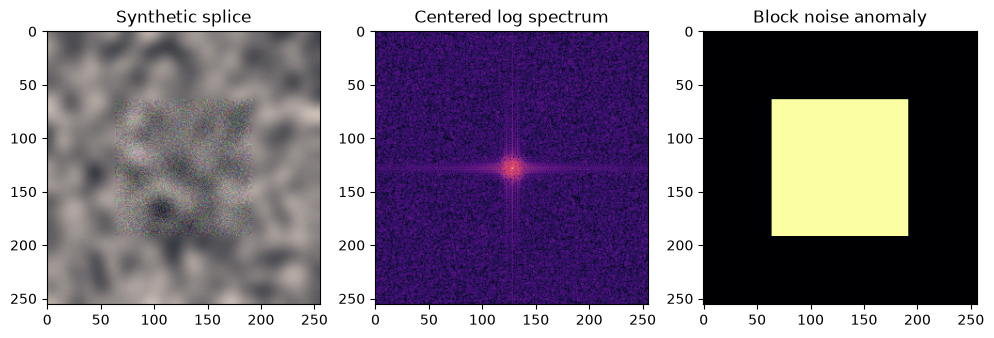

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set_title("Synthetic splice")
axes[1].imshow(result.spectrum, cmap="magma")
axes[1].set_title("Centered log spectrum")
axes[2].imshow(result.heatmap, vmin=0, vmax=1, cmap="inferno")
axes[2].set_title("Block noise anomaly")
plt.show()

## Noise and interpolation clues
The Laplacian $R=4I-I_{up}-I_{down}-I_{left}-I_{right}$ has variance $20\sigma^2$ under iid Gaussian noise. Block MAD estimates expose noise mismatch. Periodic residual-energy peaks can indicate interpolation. Texture can imitate both.

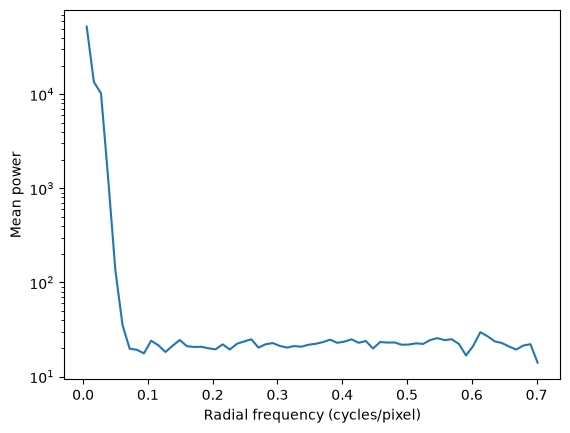

original 0.0 [('resampling', 0.0, True), ('noise', 0.0, True), ('jpeg', 0, False)]


single_jpeg 0.485 [('resampling', 0.564, True), ('noise', 0.0, True), ('jpeg', 0.08, True)]
resize 0.622 [('resampling', 0.704, True), ('noise', 0.0, True), ('jpeg', 0, False)]


rotation 0.304 [('resampling', 0.344, True), ('noise', 0.0, True), ('jpeg', 0, False)]
splice 0.867 [('resampling', 0.0, True), ('noise', 1.0, True), ('jpeg', 0, False)]


double_jpeg 0.882 [('resampling', 0.493, True), ('noise', 0.232, True), ('jpeg', 1.0, True)]


In [3]:
plt.semilogy(result.radial_frequency, result.radial_power)
plt.xlabel("Radial frequency (cycles/pixel)")
plt.ylabel("Mean power")
plt.show()
for name, (pixels, data) in samples.items():
    analysis = analyze(pixels, data)
    print(
        name,
        round(analysis.score, 3),
        [(d.name, round(d.score, 3), d.available) for d in analysis.detectors],
    )

## JPEG and fusion
Aligned quantization is approximated by $K_2=\mathrm{round}((q_1/q_2)\mathrm{round}(C/q_1))$. Decoded DCT histograms may preserve gaps. Quality pairs, decoding and grid shifts limit detection. ELA is visualization only.

Fusion: $S=0.75\max s_i+0.25\sum w_i s_i/\sum w_i$, excluding unavailable clues. No thresholds are learned. Synthetic success is not real-world accuracy.

{'name': 'jpeg', 'score': 1.0, 'available': True, 'explanation': 'Decoded DCT histograms compared with single and aligned double quantization models. Quality pair and grid alignment affect sensitivity.'}


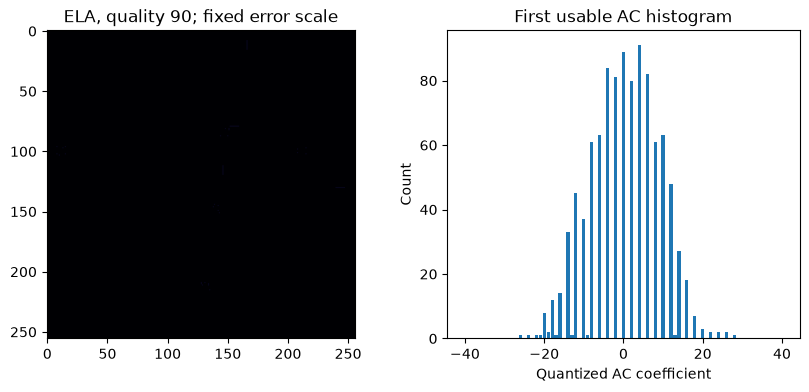

In [4]:
from fourierforensics.detectors.jpeg import ela

pixels, data = samples["double_jpeg"]
jpeg_result = analyze(pixels, data).detectors[2]
print(jpeg_result.summary())
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(ela(pixels), cmap="magma", vmin=0, vmax=0.08)
axes[0].set_title("ELA, quality 90; fixed error scale")
hist = jpeg_result.diagnostics["histograms"][0]
axes[1].bar(np.arange(-40, 41), hist["counts"][:81])
axes[1].set(xlabel="Quantized AC coefficient", ylabel="Count", title="First usable AC histogram")
plt.show()